In [5]:
from pathlib import Path
import random

import numpy as np
import pandas as pd

#Image inspection and  visualization
from PIL import Image
import matplotlib.pyplot as plt

#Building and training NN
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset

#Image datasets, preprocessing, and predefined models
from torchvision import datasets, transforms, models

#Training/validation split
from sklearn.model_selection import train_test_split


#Evaluate metrics and plots
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
from sklearn.calibration import CalibrationDisplay

from tqdm.auto import tqdm



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
path_data = Path("/Users/benz/Documents/Projects/FakeVsReal/dataset")
path_train = path_data / "train"
path_test = path_data / "test"

train_dataset = datasets.ImageFolder(root=path_train)
test_dataset = datasets.ImageFolder(root=path_test)


Numerical label: 0
Class name: FAKE
Image dimensions: (32, 32)
Colour mode: RGB


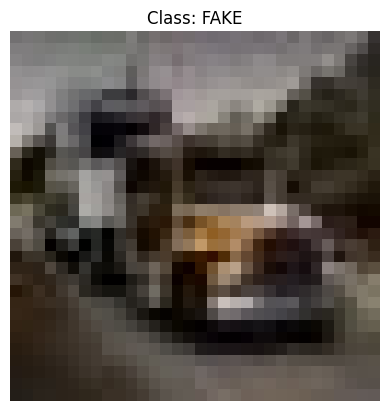

In [7]:

#Select specific image
image, label = train_dataset[0]


print("Numerical label:", label)
print("Class name:", train_dataset.classes[label])
print("Image dimensions:", image.size)
print("Colour mode:", image.mode)

plt.imshow(image)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [8]:
#Error handling for broken images and unexpected sizes
broken_images=[]
unexpected_sizes=[]

for split_name, dataset in [
    ("train", train_dataset),
    ("test", test_dataset),
]:
    for file_path, label in tqdm(
        dataset.samples,
        desc=f"Checking {split_name}"
    ):
        try:
            with Image.open(file_path) as image:
                image.load()

                if image.size != (32, 32):
                    unexpected_sizes.append(
                        (split_name, file_path, image.size)
                    )
        except (OSError, ValueError) as e:
            broken_images.append((split_name, file_path, str(e)))



print("Unreadable images:", len(broken_images))
print("Images with unexpected dimensions:", len(unexpected_sizes))

#[:5] chat suggested slicing the list to show only the first 5 entries for brevity
print("First unreadable files:", broken_images[:5])
print("First unexpected sizes:", unexpected_sizes[:5])


Checking test: 100%|██████████| 20000/20000 [00:01<00:00, 11151.50it/s]

Unreadable images: 0
Images with unexpected dimensions: 0
First unreadable files: []
First unexpected sizes: []


In [9]:
import hashlib


#Function to create a unique fingerprint for each image
def image_fingerprint(file_path):
    with Image.open(file_path) as image:
        image = image.convert("RGB")
        dimensions = str(image.size).encode("utf-8")
        pixels = image.tobytes()
        return hashlib.sha256(dimensions + pixels).hexdigest()



In [10]:
image_records = []

#Effectively convert images to a pd dataframe.
for split_name, dataset in [
    ("train", train_dataset),
    ("test", test_dataset)
]:
    for file_path, label in tqdm(
        dataset.samples, desc=f"Processing {split_name}"
        ):

        image_records.append({
            "split": split_name,
            "path":file_path,
            "class": dataset.classes[label],
            "fingerprint": image_fingerprint(file_path)
        })

image_table = pd.DataFrame(image_records)

Processing test: 100%|██████████| 20000/20000 [00:01<00:00, 12184.18it/s]


In [11]:
#Use the pd dataframe created to check for duplicates and other data errors
#Mark every member of the duplicates as true keep=False, make sure all occurrences are included in the list of duplcates.
dupes = image_table.duplicated("fingerprint", keep=False)
duplicate_rows = image_table[dupes]

split_counts = image_table.groupby("fingerprint")["split"].nunique()
overlapping_fingerprints = split_counts[split_counts > 1].index

class_counts = image_table.groupby("fingerprint")["class"].nunique()
conflicting_fingerprints = class_counts[class_counts > 1].index


#Distinct fingerprints in the dataset, each counter once
print("Distinct Fingerprints:", str(len(split_counts)))

#Total Duplicates excluding the original image
print("Duplicates:",str(120000-len(split_counts)))

#378 of them appear in both training and testing
print("Appears in Training and Test:", str(len(overlapping_fingerprints)))

print("Unique images labelled both FAKE and REAL:", str(len(conflicting_fingerprints)))


Distinct Fingerprints: 118664
Duplicates: 1336
Appears in Training and Test: 378
Unique images labelled both FAKE and REAL: 0


In [ ]:
#After reading the Kaggle where the data was sourced from. The code includes a RandomOverSampler.
#This could be the reason for the duplicates.
#Theory is that the RandomOverSampler duplicates images to balance the classes.

#Confirming theory by checking the classes of the duplicates.
print("Classes containing duplicates:", duplicate_rows["class"].unique())



Classes containing duplicates: ['FAKE']
Number of duplicates 2672
